In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import seaborn as sns
from PIL import Image

# ممیزی ساختاری مجموعه‌داده

در این Notebook، ساختار اولیه مجموعه‌داده شامل ابعاد، نوع متغیرها، شناسه‌ها، اطلاعات زمانی و مکانی، ویژگی‌های تصاویر و ارتباط میان فایل‌های فراداده و تصاویر بررسی می‌شود.

In [33]:
df = pd.read_csv("../inat_birds/dataset.csv")

In [34]:
# Dataset dimensions
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset shape: (50000, 80)
Number of rows: 50000
Number of columns: 80


In [35]:
# Column names
print("\nColumn names:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")


Column names:
1. image_path
2. image_abspath
3. label_id
4. species_scientific
5. taxon_id
6. common_name
7. iconic_taxon
8. selection_tier
9. observation_id
10. observation_uuid
11. observation_url
12. obs_taxon_id
13. obs_taxon_name
14. obs_taxon_rank
15. species_guess
16. photo_id
17. photo_position
18. photo_license
19. photo_attribution
20. photo_url
21. size_variant
22. user_id
23. user_login
24. observed_on
25. time_observed_at
26. observed_on_string
27. observed_time_zone
28. year
29. month
30. day
31. hour
32. week
33. created_at
34. updated_at
35. latitude
36. longitude
37. positional_accuracy
38. public_positional_accuracy
39. geoprivacy
40. taxon_geoprivacy
41. obscured
42. place_guess
43. place_ids
44. quality_grade
45. captive
46. identifications_count
47. num_id_agreements
48. num_id_disagreements
49. faves_count
50. comments_count
51. annotations
52. life_stage
53. sex
54. alive_or_dead
55. evidence_of_presence
56. description
57. tags
58. observation_photos_count
59. 

In [36]:
# Dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 80 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   image_path                  50000 non-null  str    
 1   image_abspath               50000 non-null  str    
 2   label_id                    50000 non-null  int64  
 3   species_scientific          50000 non-null  str    
 4   taxon_id                    50000 non-null  int64  
 5   common_name                 50000 non-null  str    
 6   iconic_taxon                50000 non-null  str    
 7   selection_tier              50000 non-null  str    
 8   observation_id              50000 non-null  int64  
 9   observation_uuid            50000 non-null  str    
 10  observation_url             50000 non-null  str    
 11  obs_taxon_id                50000 non-null  int64  
 12  obs_taxon_name              50000 non-null  str    
 13  obs_taxon_rank              50000 non-null

In [37]:
# Data types
print(df.dtypes.value_counts())

str        39
int64      23
float64    15
bool        3
Name: count, dtype: int64


In [38]:
# Column summary
structure = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "non_null": df.notna().sum().values,
    "missing": df.isna().sum().values,
    "unique_values": df.nunique().values
})

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

for i in range(0, len(structure), 20):
    display(structure.iloc[i:i+20])

,column,dtype,non_null,missing,unique_values
0,image_path,str,50000,0,50000
1,image_abspath,str,50000,0,50000
2,label_id,int64,50000,0,100
3,species_scientific,str,50000,0,100
4,taxon_id,int64,50000,0,100
5,common_name,str,50000,0,100
6,iconic_taxon,str,50000,0,1
7,selection_tier,str,50000,0,2
8,observation_id,int64,50000,0,50000
9,observation_uuid,str,50000,0,50000


,column,dtype,non_null,missing,unique_values
20,size_variant,str,50000,0,1
21,user_id,int64,50000,0,18631
22,user_login,str,50000,0,18632
23,observed_on,str,50000,0,4800
24,time_observed_at,str,48772,1228,48511
25,observed_on_string,str,50000,0,49138
26,observed_time_zone,str,50000,0,352
27,year,int64,50000,0,54
28,month,int64,50000,0,12
29,day,int64,50000,0,31


,column,dtype,non_null,missing,unique_values
40,obscured,bool,50000,0,2
41,place_guess,str,49502,498,28249
42,place_ids,str,49889,111,22237
43,quality_grade,str,50000,0,1
44,captive,bool,50000,0,1
45,identifications_count,int64,50000,0,22
46,num_id_agreements,int64,50000,0,21
47,num_id_disagreements,int64,50000,0,4
48,faves_count,int64,50000,0,17
49,comments_count,int64,50000,0,14


,column,dtype,non_null,missing,unique_values
60,file_size_bytes,int64,50000,0,48521
61,image_format,str,50000,0,2
62,exif_orientation,int64,50000,0,1
63,sha256,str,50000,0,50000
64,dhash,str,50000,0,50000
65,sharpness,float64,50000,0,45578
66,brightness,float64,50000,0,14204
67,contrast,float64,50000,0,7412
68,aspect_ratio,float64,50000,0,869
69,detector,str,50000,0,1


<div dir="rtl" align="right">

### بررسی ساختار شناسه‌ها و متغیرهای طبقه‌بندی

برای بررسی ساختار برچسب‌گذاری و شناسایی ارتباط میان گونه‌های هدف و اطلاعات تاکسونومیک ثبت‌شده در iNaturalist، تعداد مقادیر یکتای چند متغیر کلیدی بررسی شد. این متغیرها شامل شناسهٔ کلاس (`label_id`)، شناسهٔ تاکسون گونهٔ هدف (`taxon_id`)، نام علمی گونه (`species_scientific`) و شناسهٔ تاکسون ثبت‌شده برای مشاهده (`obs_taxon_id`) هستند.

نتایج نشان می‌دهد سه متغیر نخست هرکدام دارای ۱۰۰ مقدار یکتا هستند، درحالی‌که `obs_taxon_id` دارای ۳۱۱ مقدار یکتا است. این تفاوت نشان می‌دهد که اطلاعات تاکسونومیک ثبت‌شده برای مشاهدات، ساختاری متفاوت از برچسب‌های گونه‌ای تعریف‌شده در مجموعه‌داده دارد.

</div>

<div dir="rtl" align="right">

در بررسی متغیر `obs_taxon_rank`، چهار سطح تاکسونومیک مشاهده شد: گونه (Species) با ۴۴٬۹۹۰ رکورد (۸۹٫۹۸٪)، زیرگونه (Subspecies) با ۳٬۳۷۰ رکورد (۶٫۷۴٪)، واریته (Variety) با ۱٬۱۹۱ رکورد (۲٫۳۸٪) و فرم (Form) با ۴۴۹ رکورد (۰٫۹۰٪).

این توزیع نشان می‌دهد که اطلاعات تاکسونومیک ثبت‌شده برای مشاهدات همیشه در سطح گونه نیست. بنابراین، تفاوت تعداد شناسه‌های `obs_taxon_id` با تعداد گونه‌های هدف، به‌تنهایی نشان‌دهندهٔ خطا یا ناسازگاری در داده نیست و باید با توجه به ساختار سلسله‌مراتبی طبقه‌بندی زیستی تفسیر شود.

</div>

In [39]:
print(df["obs_taxon_rank"].value_counts(dropna=False))

obs_taxon_rank
species       44990
subspecies     3370
variety        1191
form            449
Name: count, dtype: int64


<div dir="rtl" align="right">

### بررسی ارتباط شناسه‌های مشاهده، تصویر و کاربر

برای بررسی ساختار شناسه‌ها و احتمال وجود رکوردهای تکراری، تعداد مقادیر یکتای متغیرهای `observation_id`، `photo_id` و `user_id` مورد بررسی قرار گرفت.

نتایج نشان داد متغیرهای `observation_id` و `photo_id` هرکدام دارای ۵۰٬۰۰۰ مقدار یکتا هستند. با توجه به برابر بودن تعداد مقادیر یکتا با تعداد کل رکوردها، هیچ شناسهٔ مشاهده یا تصویری در مجموعه‌داده تکرار نشده است.

در مقابل، متغیر `user_id` دارای ۱۸٬۶۳۱ مقدار یکتا است؛ بنابراین برخی کاربران بیش از یک مشاهده در مجموعه‌داده دارند. بااین‌حال، در فرایند جمع‌آوری داده‌ها محدودیتی اعمال شده است که از انتخاب بیش از یک مشاهده از یک کاربر برای یک گونه در یک روز جلوگیری می‌کند.

</div>

In [40]:
df.groupby(
    ["user_id", "species_scientific", "observed_on"]
).size().value_counts().sort_index()

1    50000
Name: count, dtype: int64

<div dir="rtl" align="right">

### بررسی متغیرهای زمانی

مجموعه‌داده شامل چندین متغیر زمانی است که اطلاعات مربوط به تاریخ و زمان ثبت مشاهدات را توصیف می‌کنند. این متغیرها شامل تاریخ مشاهده (`observed_on`)، زمان دقیق مشاهده (`time_observed_at`)، منطقهٔ زمانی (`observed_time_zone`) و مؤلفه‌های استخراج‌شده از تاریخ، شامل سال، ماه، روز، ساعت و هفته هستند.

این متغیرها امکان بررسی الگوهای زمانی موجود در مشاهدات را فراهم می‌کنند و می‌توانند در تحلیل توزیع زمانی داده‌ها مورد استفاده قرار گیرند.

</div>

In [41]:
temporal_columns = [
    "observed_on",
    "time_observed_at",
    "observed_on_string",
    "observed_time_zone",
    "year",
    "month",
    "day",
    "hour",
    "week"
]

temporal_summary = pd.DataFrame({
    "dtype": df[temporal_columns].dtypes.astype(str),
    "non_null": df[temporal_columns].notna().sum(),
    "missing": df[temporal_columns].isna().sum(),
    "unique_values": df[temporal_columns].nunique()
})

display(temporal_summary)

,dtype,non_null,missing,unique_values
observed_on,str,50000,0,4800
time_observed_at,str,48772,1228,48511
observed_on_string,str,50000,0,49138
observed_time_zone,str,50000,0,352
year,int64,50000,0,54
month,int64,50000,0,12
day,int64,50000,0,31
hour,int64,50000,0,24
week,int64,50000,0,53


<div dir="rtl" align="right">

### بررسی متغیرهای جغرافیایی

مجموعه‌داده شامل متغیرهای مختلفی برای توصیف موقعیت مکانی مشاهدات است. این متغیرها شامل مختصات جغرافیایی (عرض و طول جغرافیایی)، میزان دقت مختصات ثبت‌شده، اطلاعات مربوط به حریم خصوصی موقعیت مکانی و نام و شناسهٔ مکان‌های مرتبط با هر مشاهده هستند.

متغیرهای `latitude` و `longitude` موقعیت جغرافیایی مشاهده را مشخص می‌کنند. متغیرهای `positional_accuracy` و `public_positional_accuracy` به میزان دقت مختصات ثبت‌شده و مختصات عمومی‌شده اشاره دارند. همچنین، `geoprivacy` و `taxon_geoprivacy` وضعیت محدودیت دسترسی به اطلاعات مکانی را مشخص می‌کنند.

دو متغیر `place_guess` و `place_ids` نیز به‌ترتیب شامل نام مکان تخمین‌زده‌شده و شناسه‌های مکان‌های مرتبط با مشاهده هستند. در نهایت، متغیر `obscured` مشخص می‌کند که موقعیت مکانی مشاهده به دلایل مربوط به حریم خصوصی یا حفاظت از گونه، مخفی یا مبهم شده است یا خیر.

</div>

In [42]:
geo_columns = [
    "latitude",
    "longitude",
    "positional_accuracy",
    "public_positional_accuracy",
    "geoprivacy",
    "taxon_geoprivacy",
    "obscured",
    "place_guess",
    "place_ids"
]

geo_summary = pd.DataFrame({
    "dtype": df[geo_columns].dtypes.astype(str),
    "non_null": df[geo_columns].notna().sum(),
    "missing": df[geo_columns].isna().sum(),
    "unique_values": df[geo_columns].nunique()
})

display(geo_summary)

,dtype,non_null,missing,unique_values
latitude,float64,49918,82,47648
longitude,float64,49918,82,47634
positional_accuracy,float64,41437,8563,4668
public_positional_accuracy,float64,42081,7919,4704
geoprivacy,str,2803,47197,2
taxon_geoprivacy,str,47798,2202,3
obscured,bool,50000,0,2
place_guess,str,49502,498,28249
place_ids,str,49889,111,22237


<div dir="rtl" align="right">

### نتایج بررسی متغیرهای شناسایی و اطلاعات مشاهدات

نتایج نشان می‌دهد متغیرهای `quality_grade` و `captive` در تمام رکوردها دارای مقدار هستند، اما هرکدام تنها یک مقدار یکتا دارند و در نتیجه در مجموعه‌داده تغییرپذیری ندارند. متغیرهای مربوط به تعداد شناسایی‌ها و میزان توافق یا اختلاف میان کاربران نیز فاقد مقدار گمشده هستند.

در مقابل، برخی از متغیرهای توصیف‌کنندهٔ ویژگی‌های زیستی، مانند `life_stage` و `sex`، دارای مقادیر گمشده قابل‌توجهی هستند. این مسئله در متغیرهای متنی `description` و `tags` نیز مشاهده می‌شود؛ به‌طوری‌که بخش عمده‌ای از مشاهدات فاقد توضیحات یا برچسب‌های متنی هستند.

همچنین، متغیر `evidence_of_presence` با وجود داشتن ۴٬۱۶۰ مقدار گمشده، تنها یک مقدار یکتا در میان مقادیر ثبت‌شده دارد. این موضوع نشان می‌دهد که این متغیر در مجموعه‌داده تنوعی ندارد.

در مجموع، اگرچه بخش عمده‌ای از اطلاعات مربوط به شناسایی مشاهدات کامل است، متغیرهای توصیفی و برخی ویژگی‌های زیستی پوشش محدودتری دارند. همچنین متغیرهای فاقد تغییرپذیری، در تحلیل‌های بعدی باید با توجه به کاربردشان مورد توجه قرار گیرند.

</div>

In [43]:
observation_columns = [
    "quality_grade",
    "captive",
    "identifications_count",
    "num_id_agreements",
    "num_id_disagreements",
    "faves_count",
    "comments_count",
    "annotations",
    "life_stage",
    "sex",
    "alive_or_dead",
    "evidence_of_presence",
    "description",
    "tags"
]

observation_summary = pd.DataFrame({
    "dtype": df[observation_columns].dtypes.astype(str),
    "non_null": df[observation_columns].notna().sum(),
    "missing": df[observation_columns].isna().sum(),
    "unique_values": df[observation_columns].nunique()
})

display(observation_summary)

,dtype,non_null,missing,unique_values
quality_grade,str,50000,0,1
captive,bool,50000,0,1
identifications_count,int64,50000,0,22
num_id_agreements,int64,50000,0,21
num_id_disagreements,int64,50000,0,4
faves_count,int64,50000,0,17
comments_count,int64,50000,0,14
annotations,str,46029,3971,44
life_stage,str,26978,23022,2
sex,str,9398,40602,3


In [44]:
image_columns = [
    "width",
    "height",
    "file_size_bytes",
    "image_format",
    "exif_orientation",
    "size_variant",
    "sha256",
    "dhash",
    "sharpness",
    "brightness",
    "contrast",
    "aspect_ratio"
]

image_summary = pd.DataFrame({
    "dtype": df[image_columns].dtypes.astype(str),
    "non_null": df[image_columns].notna().sum(),
    "missing": df[image_columns].isna().sum(),
    "unique_values": df[image_columns].nunique()
})

display(image_summary)

,dtype,non_null,missing,unique_values
width,int64,50000,0,637
height,int64,50000,0,640
file_size_bytes,int64,50000,0,48521
image_format,str,50000,0,2
exif_orientation,int64,50000,0,1
size_variant,str,50000,0,1
sha256,str,50000,0,50000
dhash,str,50000,0,50000
sharpness,float64,50000,0,45578
brightness,float64,50000,0,14204


<div dir="rtl" align="right">

### بررسی ارتباط فایل فراداده با تصاویر

برای اطمینان از یکپارچگی مجموعه‌داده، مسیرهای ذخیره‌شده در ستون `image_path` با فایل‌های موجود در پوشهٔ تصاویر تطبیق داده شدند. از آنجا که مسیرهای ثبت‌شده به‌صورت نسبی هستند، برای دسترسی به فایل‌ها مسیر پایهٔ `../inat_birds/` به آن‌ها اضافه شد.

در این بررسی، وجود هر فایل در مسیر متناظر آن کنترل شد تا مشخص شود آیا تمام رکوردهای فایل فراداده به تصاویر واقعی و قابل‌دسترسی اشاره می‌کنند یا خیر.

</div>

In [45]:
from pathlib import Path

image_root = Path("../inat_birds")

exists = df["image_path"].apply(
    lambda p: (image_root / p).is_file()
)

print("Total records:", len(df))
print("Existing images:", exists.sum())
print("Missing images:", (~exists).sum())
print("Existence rate:", f"{exists.mean() * 100:.2f}%")

Total records: 50000
Existing images: 50000
Missing images: 0
Existence rate: 100.00%


<div dir="rtl" align="right">

### بررسی توزیع تعداد نمونه‌ها بین گونه‌ها

به‌منظور بررسی توازن کلاس‌ها، تعداد تصاویر اختصاص‌یافته به هر یک از ۱۰۰ گونه محاسبه شد. نتایج نشان داد که تمام گونه‌ها دقیقاً دارای ۵۰۰ تصویر هستند. میانگین تعداد تصاویر در هر کلاس برابر با ۵۰۰ و انحراف معیار آن صفر است.

بنابراین، مجموعه‌داده از نظر تعداد نمونه‌های متعلق به کلاس‌های مختلف کاملاً متوازن است و از این نظر با مسئلهٔ عدم‌توازن کلاس‌ها مواجه نیست.

</div>

In [46]:
species_counts = df["species_scientific"].value_counts().sort_values()

print("Number of species:", len(species_counts))
print("Minimum images per species:", species_counts.min())
print("Maximum images per species:", species_counts.max())
print("Mean images per species:", species_counts.mean())
print("Standard deviation:", species_counts.std())

display(species_counts.describe())

Number of species: 100
Minimum images per species: 500
Maximum images per species: 500
Mean images per species: 500.0
Standard deviation: 0.0


count    100.0
mean     500.0
std        0.0
min      500.0
25%      500.0
50%      500.0
75%      500.0
max      500.0
Name: count, dtype: float64

<div dir="rtl" align="right">

که نتایج نشان می‌دهد که تمام فایل‌ها موجود هستند.

</div>

# data_flow_diagram
![Data Flow Diagram](../assets/data_flow_diagram.png)

<div dir="rtl" align="right">

# ممیزی کیفیت داده

</div>

<div dir="rtl" align="right">

### تحلیل مقادیر گمشده

بررسی مقادیر گمشده نشان می‌دهد که میزان داده‌های ناقص در متغیرهای مختلف یکسان نیست. ستون‌هایی مانند `geoprivacy`، `tags`، `description` و `sex` بیشترین میزان مقادیر گمشده را دارند. این موضوع تا حد زیادی می‌تواند ناشی از اختیاری بودن ثبت برخی اطلاعات در سامانه iNaturalist باشد.

در مقابل، متغیرهای اصلی مربوط به تصاویر و برچسب گونه‌ها فاقد مقدار گمشده هستند و مختصات جغرافیایی نیز برای بیش از ۹۹.۸٪ رکوردها موجود است.

در تصمیم اولیه، ویژگی‌های geoprivacy, tages, description, sex, life_stage را به دلیل مقادیر نامعلوم خیلی زیاد حذف می‌کنیم. نحوه برخورد با این مقادیر در مراحل بعدی و با توجه به کاربرد هر متغیر در تحلیل‌ها و مدل‌سازی تعیین خواهد شد.

</div>

In [47]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})

missing_summary = missing_summary.sort_values(
    "missing_percent", ascending=False
)

display(missing_summary[missing_summary["missing_count"] > 0])

,missing_count,missing_percent
geoprivacy,47197,94.39
tags,46773,93.55
description,43882,87.76
sex,40602,81.20
life_stage,23022,46.04
positional_accuracy,8563,17.13
public_positional_accuracy,7919,15.84
alive_or_dead,6194,12.39
evidence_of_presence,4160,8.32
annotations,3971,7.94


<div dir="rtl" align="right">

### تحلیل رکوردهای تکراری

نتایج بررسی نشان می‌دهد که هیچ ردیف کاملاً تکراری و هیچ تکراری در شناسه‌های `observation_id` و `photo_id` وجود ندارد. همچنین تمام مقادیر `sha256` یکتا هستند؛ بنابراین هیچ فایل تصویری کاملاً یکسانی در مجموعه‌داده شناسایی نشد.

در تصمیم اولیه، نیازی به حذف رکورد بر اساس تکرارهای دقیق وجود ندارد. با این حال، احتمال وجود تصاویر مشابه با تفاوت‌های جزئی همچنان وجود دارد که با بررسی هش ادراکی قابل ارزیابی است.

</div>

In [48]:
duplicate_summary = pd.Series({
    "Fully duplicated rows": df.duplicated().sum(),
    "Duplicate observation_id": df["observation_id"].duplicated().sum(),
    "Duplicate photo_id": df["photo_id"].duplicated().sum(),
    "Duplicate SHA256": df["sha256"].duplicated().sum()
}, name="duplicate_count")

display(duplicate_summary.to_frame())

,duplicate_count
Fully duplicated rows,0
Duplicate observation_id,0
Duplicate photo_id,0
Duplicate SHA256,0


<div dir="rtl" align="right">

### تحلیل مقادیر ناممکن

برای بررسی اعتبار مقادیر عددی، محدوده‌های منطقی متغیرهای زمانی، جغرافیایی، مشخصات تصاویر، معیارهای کیفیت و اطلاعات مشاهدات بررسی شدند.

نتایج نشان داد که در هیچ‌یک از ۱۹ متغیر بررسی‌شده، مقدار خارج از محدوده معتبر مشاهده نمی‌شود. بنابراین، در بررسی اولیه نیازی به حذف یا اصلاح رکوردها بر اساس این معیارها وجود ندارد.

لازم به ذکر است که قرار گرفتن مقادیر در محدوده منطقی، لزوماً صحت واقعی آن‌ها را تضمین نمی‌کند.

</div>

In [49]:
invalid_checks = {
    "latitude": df["latitude"].notna() & ~df["latitude"].between(-90, 90),
    "longitude": df["longitude"].notna() & ~df["longitude"].between(-180, 180),
    "month": ~df["month"].between(1, 12),
    "day": ~df["day"].between(1, 31),
    "hour": ~df["hour"].between(0, 23),
    "week": ~df["week"].between(1, 53),

    "width": df["width"] <= 0,
    "height": df["height"] <= 0,
    "file_size_bytes": df["file_size_bytes"] <= 0,

    "brightness": ~df["brightness"].between(0, 255),
    "bird_conf": ~df["bird_conf"].between(0, 1),
    "bird_area_frac": ~df["bird_area_frac"].between(0, 1),
    "aspect_ratio": df["aspect_ratio"] <= 0,

    "sharpness": df["sharpness"] < 0,
    "contrast": df["contrast"] < 0,
    "bird_sharpness": df["bird_sharpness"] < 0,

    "identifications_count": df["identifications_count"] < 0,
    "faves_count": df["faves_count"] < 0,
    "comments_count": df["comments_count"] < 0,
}

invalid_summary = pd.DataFrame({
    "invalid_count": {
        col: mask.sum() for col, mask in invalid_checks.items()
    }
})

display(invalid_summary)

,invalid_count
latitude,0
longitude,0
month,0
day,0
hour,0
week,0
width,0
height,0
file_size_bytes,0
brightness,0


<div dir="rtl" align="right">

### تحلیل ناسازگاری نوع داده

نوع داده ۱۱ متغیر منتخب با توجه به ماهیت آن‌ها بررسی شد. نتایج نشان داد که متغیرهای عددی، رشته‌ای و بولی همگی دارای نوع داده مناسب هستند.

در نتیجه، در بررسی اولیه ناسازگاری نوع داده‌ای در متغیرهای بررسی‌شده مشاهده نشد و نیازی به اصلاح نوع داده آن‌ها وجود ندارد. متغیر `observed_on` نیز در صورت نیاز به تحلیل‌های زمانی، در مرحله مربوطه به قالب تاریخ تبدیل خواهد شد.

</div>

In [50]:
type_checks = {
    "year": pd.api.types.is_numeric_dtype(df["year"]),
    "month": pd.api.types.is_numeric_dtype(df["month"]),
    "latitude": pd.api.types.is_numeric_dtype(df["latitude"]),
    "longitude": pd.api.types.is_numeric_dtype(df["longitude"]),
    "width": pd.api.types.is_numeric_dtype(df["width"]),
    "height": pd.api.types.is_numeric_dtype(df["height"]),
    "brightness": pd.api.types.is_numeric_dtype(df["brightness"]),
    "sharpness": pd.api.types.is_numeric_dtype(df["sharpness"]),
    "observed_on": pd.api.types.is_string_dtype(df["observed_on"]),
    "obscured": pd.api.types.is_bool_dtype(df["obscured"]),
    "captive": pd.api.types.is_bool_dtype(df["captive"])
}

display(pd.DataFrame.from_dict(
    type_checks, orient="index", columns=["type_is_appropriate"]
))

,type_is_appropriate
year,True
month,True
latitude,True
longitude,True
width,True
height,True
brightness,True
sharpness,True
observed_on,True
obscured,True


<div dir="rtl">

## تحلیل مقادیر پرت (Outlier Analysis)

برای شناسایی مقادیر پرت در ویژگی‌های عددی مجموعه‌داده، از سه روش **محدوده بین چارکی (IQR)**، **انحراف مطلق میانه (MAD)** و **صدک‌های اول و نودونهم (1st–99th Percentile)** استفاده شده است. استفاده از چند روش امکان مقایسه‌ی حساسیت آن‌ها به توزیع داده‌ها و شناسایی ویژگی‌هایی را فراهم می‌کند که رفتار غیرمعمول‌تری دارند.

### ۱. روش IQR

در این روش، مقادیر خارج از بازه‌ی زیر به‌عنوان داده‌ی پرت در نظر گرفته می‌شوند:

$$
[Q_1-1.5IQR,\ Q_3+1.5IQR]
$$

نتایج نشان می‌دهند که `aspect_ratio` با **۱۶٫۸۳٪** بیشترین درصد مقادیر پرت را دارد. پس از آن، `bird_sharpness` با ۷٫۴۶٪، `sharpness` با ۶٫۵۷٪ و `width` با ۴٫۵۹٪ قرار می‌گیرند.

نکته‌ی قابل‌توجه، تعداد نسبتاً زیاد مقادیر پرت در `aspect_ratio` است. این موضوع می‌تواند نشان‌دهنده‌ی تنوع قابل‌توجه در نسبت ابعاد تصاویر باشد؛ برای مثال، تصاویر با قاب‌بندی افقی یا عمودی متفاوت. بنابراین، این مقادیر لزوماً نشان‌دهنده‌ی تصاویر نامعتبر نیستند.

در مقابل، متغیرهایی مانند `contrast` و `file_size_bytes` به‌ترتیب تنها ۰٫۵۸٪ و ۱٫۸۱٪ مقدار پرت دارند. همچنین برای `height` هیچ مقدار پرت شناسایی نشده است.

حد پایین منفی برای برخی ویژگی‌ها مانند `file_size_bytes` و `bird_area_frac` از نظر فیزیکی معنای معتبری ندارد. این مسئله ناشی از ماهیت آماری فرمول IQR است و به این معنا نیست که مقادیر منفی واقعاً در داده‌ها وجود دارند.

### ۲. روش MAD

در روش MAD، فاصله‌ی هر مشاهده از میانه با استفاده از انحراف مطلق میانه سنجیده می‌شود. این روش در مقایسه با IQR کمتر تحت تأثیر مقادیر بسیار بزرگ یا کوچک قرار می‌گیرد.

نتایج نشان می‌دهند که `bird_sharpness` با ۷٫۲۴۶٪ و `sharpness` با ۶٫۷۲۸٪ همچنان بیشترین درصد مقادیر پرت را دارند. این موضوع نشان می‌دهد که مقادیر غیرمعمول در معیارهای وضوح تصویر، صرفاً حاصل انتخاب روش IQR نیستند و در روش MAD نیز مشاهده می‌شوند.

در مقابل، درصد مقادیر پرت در برخی ویژگی‌ها به‌طور محسوسی کاهش یافته است:

- `aspect_ratio` از ۱۶٫۸۳٪ در IQR به ۰٫۴۳۸٪ در MAD رسیده است.
- `brightness` از ۳٫۴۹٪ به ۰٫۶۵۴٪ کاهش یافته است.
- `file_size_bytes` از ۱٫۸۱٪ به ۰٫۵۳۴٪ رسیده است.
- `contrast` نیز تنها ۰٫۰۴۶٪ مقدار پرت دارد.

این اختلاف نشان می‌دهد که شناسایی مقادیر پرت در این ویژگی‌ها به روش تشخیص وابستگی قابل‌توجهی دارد.

یک نکته‌ی مهم درباره‌ی `width` وجود دارد: مقدار MAD آن صفر است؛ زیرا میانه‌ی داده‌ها ۱۰۲۴ پیکسل و بخش بزرگی از تصاویر دارای همین عرض هستند. در چنین شرایطی، معیار MAD توانایی مناسبی برای تشخیص مقادیر پرت ندارد. بنابراین، صفر بودن تعداد مقادیر پرت در این ویژگی را نباید به معنای نبود مقادیر غیرعادی تلقی کرد.

### ۳. روش صدک‌های اول و نودونهم

در این روش، مقادیر پایین‌تر از صدک اول و بالاتر از صدک نودونهم به‌عنوان مقادیر پرت علامت‌گذاری شده‌اند.

برای بیشتر ویژگی‌ها، تقریباً ۲٪ از مشاهدات به‌عنوان مقادیر پرت شناسایی شده‌اند؛ این نتیجه تا حد زیادی قابل انتظار است، زیرا بازه‌ی صدک اول تا نودونهم تقریباً ۹۸٪ داده‌ها را در بر می‌گیرد.

برای مثال:

- `file_size_bytes` و `brightness` هرکدام ۲٪ مقدار پرت دارند.
- `sharpness` و `bird_sharpness` نیز تقریباً ۲٪ مقادیر پرت دارند.
- `bird_area_frac` با ۱٫۹۹۲٪ مقدار پرت در همین محدوده قرار می‌گیرد.

در مقابل، برای `width` و `height` به‌ترتیب ۰٫۸۶۴٪ و ۰٫۹۹۲٪ مقدار پرت شناسایی شده است. این موضوع می‌تواند ناشی از تمرکز مقادیر این ویژگی‌ها در چند اندازه‌ی متداول تصویر باشد.

همچنین `aspect_ratio` تنها ۰٫۶۱۴٪ مقدار پرت دارد. این نتیجه در مقایسه با ۱۶٫۸۳٪ در روش IQR اختلاف قابل‌توجهی را نشان می‌دهد.

نکته‌ی دیگر، شناسایی ۱٫۲۴٪ مقدار پرت در `bird_conf` است. این ویژگی برخلاف دو روش قبلی، در جدول صدکی بررسی شده است و نتایج آن نشان می‌دهند که تعداد محدودی از نمونه‌ها دارای اطمینان تشخیص نسبتاً پایین‌تری هستند. با این حال، پایین بودن `bird_conf` به‌تنهایی به معنای اشتباه بودن تشخیص پرنده نیست.

### ۴. مقایسه و جمع‌بندی روش‌ها

مقایسه‌ی سه روش نشان می‌دهد که میزان حساسیت آن‌ها به توزیع ویژگی‌ها متفاوت است.

| ویژگی | IQR (%) | MAD (%) | صدکی (%) |
|---|---:|---:|---:|
| `width` | 4.59 | 0.00 | 0.864 |
| `height` | 0.00 | 0.00 | 0.992 |
| `file_size_bytes` | 1.81 | 0.534 | 2.00 |
| `sharpness` | 6.57 | 6.728 | 1.998 |
| `brightness` | 3.49 | 0.654 | 2.00 |
| `contrast` | 0.58 | 0.046 | 1.996 |
| `aspect_ratio` | 16.83 | 0.438 | 0.614 |
| `bird_area_frac` | 3.48 | 3.124 | 1.992 |
| `bird_sharpness` | 7.46 | 7.246 | 2.00 |

*توجه: `bird_conf` فقط در تحلیل صدکی بررسی شده است.*

از این مقایسه چند نتیجه‌ی مهم به دست می‌آید:

1. **پایداری نتایج برای ویژگی‌های وضوح تصویر:** در هر سه روش، `sharpness` و `bird_sharpness` سهم قابل‌توجهی از مقادیر پرت را نشان می‌دهند. به‌ویژه توافق IQR و MAD نشان می‌دهد که این ویژگی‌ها دارای مقادیر دورافتاده‌ای هستند که ارزش بررسی بیشتر دارند.

2. **حساسیت بالای IQR به نسبت ابعاد:** اختلاف زیاد نتایج `aspect_ratio` میان IQR و دو روش دیگر نشان می‌دهد که توزیع این ویژگی احتمالاً به شکلی است که مرزهای چارکی، بخش قابل‌توجهی از مقادیر را خارج از محدوده‌ی معمول قرار می‌دهند. این مقادیر ممکن است ناشی از تنوع طبیعی در جهت و قاب‌بندی تصاویر باشند.

3. **تفاوت در شناسایی مقادیر پرت روشنایی و کنتراست:** روش MAD تعداد بسیار کمتری از مقادیر پرت را در این دو ویژگی شناسایی می‌کند. بنابراین، نمی‌توان تمام مشاهدات علامت‌گذاری‌شده توسط IQR را الزاماً غیرعادی یا نامعتبر دانست.

4. **محدودیت روش‌ها در ویژگی‌های دارای مقادیر تکراری:** نتیجه‌ی MAD برای `width` نشان می‌دهد که در توزیع‌هایی با تمرکز شدید روی یک مقدار، این روش ممکن است توانایی تشخیص مناسبی نداشته باشد.

5. **نقش روش صدکی:** این روش بیشتر برای شناسایی نمونه‌های واقع در دو انتهای توزیع مناسب است و به‌دلیل تعریف آن، برای بسیاری از ویژگی‌ها تقریباً ۲٪ داده‌ها را علامت‌گذاری می‌کند. بنابراین، به‌تنهایی شواهد مستقلی برای غیرعادی بودن داده‌ها ارائه نمی‌دهد.

### ۵. تصمیم درباره‌ی حذف داده‌های پرت

با توجه به ماهیت تصویری مجموعه‌داده، حذف خودکار نمونه‌ها بر اساس نتایج این روش‌ها توصیه نمی‌شود. مقادیر غیرمعمول ممکن است بازتاب‌دهنده‌ی تنوع واقعی تصاویر باشند؛ برای مثال، یک پرنده ممکن است در فاصله‌ی دور از دوربین ثبت شده باشد و در نتیجه `bird_area_frac` کوچکی داشته باشد، یا تصویر آن به دلیل شرایط محیطی وضوح پایینی داشته باشد.

از طرف دیگر، چنین نمونه‌هایی ممکن است شامل تصاویر نامناسب، تشخیص اشتباه پرنده یا نمونه‌هایی باشند که پرنده در آن‌ها به‌درستی قابل مشاهده نیست.

بنابراین، بهتر است نمونه‌های علامت‌گذاری‌شده، به‌ویژه موارد دارای `bird_area_frac`، `sharpness` و `bird_sharpness` بسیار پایین، به‌صورت بصری بررسی شوند. این بررسی کمک می‌کند میان تنوع طبیعی داده‌ها و مشکلات واقعی کیفیت تصویر تمایز قائل شویم.

**در مجموع، هدف این مرحله حذف تمام مقادیر پرت نیست؛ بلکه شناسایی نمونه‌های نیازمند بررسی بیشتر و جلوگیری از حذف ناخواسته‌ی تنوع طبیعی مجموعه‌داده است.**

</div>

In [51]:
outlier_columns = [
    "width", "height", "file_size_bytes",
    "sharpness", "brightness", "contrast",
    "aspect_ratio", "bird_area_frac",
    "bird_sharpness"
]

outlier_summary = []

for col in outlier_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = (df[col] < lower) | (df[col] > upper)

    outlier_summary.append({
        "column": col,
        "lower_bound": round(lower, 3),
        "upper_bound": round(upper, 3),
        "outlier_count": mask.sum(),
        "outlier_percent": round(mask.mean() * 100, 2)
    })

outlier_summary = pd.DataFrame(outlier_summary)
display(outlier_summary)

,column,lower_bound,upper_bound,outlier_count,outlier_percent
0,width,591.500,1283.500,2293,4.59
1,height,171.500,1535.500,0,0.00
2,file_size_bytes,-357418.000,1146296.000,906,1.81
3,sharpness,-1680.514,3971.276,3285,6.57
4,brightness,51.205,207.405,1746,3.49
5,contrast,-1.110,85.770,288,0.58
6,aspect_ratio,1.084,1.748,8413,16.83
7,bird_area_frac,-0.206,0.585,1738,3.48
8,bird_sharpness,-847.644,2107.506,3732,7.46


In [52]:
columns = [
    "width", "height", "file_size_bytes",
    "sharpness", "brightness", "contrast",
    "aspect_ratio", "bird_area_frac",
    "bird_sharpness"
]

results = []

for col in columns:
    x = pd.to_numeric(df[col], errors="coerce").dropna()

    median = x.median()
    mad = np.median(np.abs(x - median))

    if mad == 0:
        outliers = 0
    else:
        modified_z = 0.6745 * (x - median) / mad
        outliers = (np.abs(modified_z) > 3.5).sum()

    results.append({
        "feature": col,
        "median": median,
        "MAD": mad,
        "outlier_count": outliers,
        "outlier_percentage": outliers / len(x) * 100
    })

mad_results = pd.DataFrame(results)

mad_results

,feature,median,MAD,outlier_count,outlier_percentage
0,width,1024.000000,0.000000,0,0.000
1,height,768.000000,85.000000,0,0.000
2,file_size_bytes,370518.500000,182104.000000,267,0.534
3,sharpness,915.885000,581.185000,3364,6.728
4,brightness,128.150000,19.420000,327,0.654
5,contrast,42.200000,10.850000,23,0.046
6,aspect_ratio,1.333000,0.166000,219,0.438
7,bird_area_frac,0.161475,0.083975,1562,3.124
8,bird_sharpness,517.715000,312.645000,3623,7.246


In [53]:
columns = [
    "width",
    "height",
    "file_size_bytes",
    "sharpness",
    "brightness",
    "contrast",
    "aspect_ratio",
    "bird_conf",
    "bird_area_frac",
    "bird_sharpness"
]

results = []

for col in columns:
    x = pd.to_numeric(df[col], errors="coerce").dropna()

    lower = x.quantile(0.01)
    upper = x.quantile(0.99)

    outliers = ((x < lower) | (x > upper)).sum()

    results.append({
        "feature": col,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": outliers,
        "outlier_percentage": outliers / len(x) * 100
    })

percentile_results = pd.DataFrame(results)

percentile_results

,feature,lower_bound,upper_bound,outlier_count,outlier_percentage
0,width,473.00000,1.024000e+03,432,0.864
1,height,457.00000,1.024000e+03,496,0.992
2,file_size_bytes,40041.71000,1.234727e+06,1000,2.000
3,sharpness,54.14000,6.967253e+03,999,1.998
4,brightness,50.09970,2.219501e+02,1000,2.000
5,contrast,11.73000,8.211000e+01,998,1.996
6,aspect_ratio,1.00000,2.165000e+00,307,0.614
7,bird_conf,0.32540,9.998000e-01,620,1.240
8,bird_area_frac,0.05128,7.103954e-01,996,1.992
9,bird_sharpness,32.12950,4.666736e+03,1000,2.000


<div dir="rtl" align="right">

### تحلیل توزیع متغیرهای عددی

به‌منظور بررسی ویژگی‌های عددی مجموعه‌داده، شاخص‌های آماری شامل میانگین، میانه، انحراف معیار، چارک‌ها، حداقل، حداکثر و چولگی محاسبه شدند. همچنین برای بررسی شکل توزیع متغیرها، هیستوگرام آن‌ها رسم شد.

#### ویژگی‌های ابعادی و حجمی تصاویر

عرض تصویر (`width`) دارای میانگین 940.94 و میانه 1024 است. چولگی منفی این متغیر (1.575-) و تمرکز مقادیر در عرض 1024 نشان می‌دهد که تعداد زیادی از تصاویر دارای این عرض هستند. در مقابل، ارتفاع تصویر (`height`) با میانگین 798.78 و میانه 768، توزیعی نسبتاً متقارن دارد.

در متغیر حجم فایل (`file_size_bytes`)، میانگین حدود 423 کیلوبایت و میانه حدود 371 کیلوبایت است. چولگی مثبت 1.119 نشان‌دهنده وجود تعدادی تصویر با حجم بسیار بالاتر از مقادیر معمول است. متغیر وضوح تصویر (`sharpness`) نیز با میانگین 1415.07، میانه 915.89 و چولگی مثبت 2.338، توزیعی راست‌چوله دارد؛ به این معنا که بیشتر مقادیر در محدوده پایین‌تر قرار گرفته‌اند و تعدادی مقدار بزرگ‌تر در دنباله توزیع دیده می‌شوند.

#### ویژگی‌های نوری و نسبت ابعاد

متغیر روشنایی (`brightness`) با میانگین 130.25 و میانه 128.15 و متغیر کنتراست (`contrast`) با میانگین 42.78 و میانه 42.20، توزیع‌هایی نسبتاً متقارن دارند.

نسبت ابعاد تصویر (`aspect_ratio`) دارای میانگین 1.392 و میانه 1.333 است. چولگی مثبت 0.682 نشان می‌دهد که تعدادی از تصاویر نسبت ابعادی بزرگ‌تری دارند، در حالی که بخش قابل‌توجهی از تصاویر در حوالی نسبت 1.33 متمرکز هستند.

#### ویژگی‌های زمانی

در بررسی متغیر سال ثبت مشاهده (`year`)، میانگین برابر با 2024.26 و میانه برابر با 2026 است. انحراف معیار 3.832 و دامنه تغییرات از سال 1955 تا 2026 است. چولگی منفی قابل‌توجه (4.776-) نشان‌دهنده تمرکز مشاهدات در سال‌های اخیر و وجود دنباله‌ای به سمت سال‌های قدیمی‌تر است.

متغیر ماه (`month`) دارای میانگین 6.434 و میانه 6 است. چولگی بسیار نزدیک به صفر (0.031) نشان‌دهنده تقارن نسبی توزیع است. همچنین بررسی نمودار فراوانی ماهانه نشان می‌دهد که تعداد مشاهدات ثبت‌شده در ماه‌های مختلف تقریباً یکسان است. بنابراین، مجموعه‌داده از نظر زمان ثبت مشاهدات در سطح ماه، توزیع نسبتاً متعادلی دارد و عدم توازن زمانی قابل‌توجهی مشاهده نمی‌شود.

#### ویژگی‌های جغرافیایی

مختصات عرض جغرافیایی (`latitude`) دارای میانگین 25.15 و میانه 38.68 و مختصات طول جغرافیایی (`longitude`) دارای میانگین 3.82 و میانه 4.82 است. دامنه تغییرات این دو متغیر به‌ترتیب از 78.586- تا 80.849 و از 179.980- تا 178.814 است که گستردگی دامنه جغرافیایی مشاهدات را نشان می‌دهد.

با این حال، به دلیل ماهیت جغرافیایی مختصات، شاخص‌هایی مانند میانگین، انحراف معیار و چولگی به‌تنهایی توصیف مناسبی از پراکندگی مکانی ارائه نمی‌کنند؛ به‌ویژه اینکه طول جغرافیایی در بازه 180- تا 180+ تعریف می‌شود و مقادیر نزدیک به دو انتهای این بازه می‌توانند از نظر مکانی به یکدیگر نزدیک باشند. بنابراین، برای بررسی دقیق‌تر الگوی پراکندگی و تراکم جغرافیایی تصاویر، از نمودارهای مکانی و نمودار سه‌بعدی تراکم استفاده خواهد شد.

#### جمع‌بندی

نتایج نشان می‌دهند که ویژگی‌های عددی مجموعه‌داده از توزیع‌های متفاوتی برخوردارند. برخی متغیرها مانند روشنایی و کنتراست توزیعی نسبتاً متقارن دارند، در حالی که متغیرهایی مانند وضوح تصویر، حجم فایل و سال ثبت مشاهده دارای چولگی قابل‌توجه هستند. همچنین توزیع ماهانه تصاویر تقریباً متعادل است و مختصات جغرافیایی دامنه گسترده‌ای دارند که بررسی دقیق‌تر پراکندگی آن‌ها به تحلیل‌های بصری نیاز دارد.

این ویژگی‌ها در مراحل بعدی تحلیل و پیش‌پردازش داده‌ها مورد توجه قرار خواهند گرفت.

</div>

In [54]:
numeric_columns = [
    "width",
    "height",
    "file_size_bytes",
    "sharpness",
    "brightness",
    "contrast",
    "aspect_ratio",
    "year",
    "month",
    "latitude",
    "longitude",
]

numeric_summary = df[numeric_columns].describe().T

numeric_summary["median"] = df[numeric_columns].median()
numeric_summary["skewness"] = df[numeric_columns].skew()

numeric_summary = numeric_summary[
    ["mean", "median", "std", "min", "25%", "50%", "75%",
     "max", "skewness"]
]

display(numeric_summary.round(3))

,mean,median,std,min,25%,50%,75%,max,skewness
width,940.935,1024.000,144.131,385.000,851.000,1024.000,1024.000,1024.000,-1.575
height,798.783,768.000,158.935,384.000,683.000,768.000,1024.000,1024.000,0.243
file_size_bytes,423403.458,370518.500,276039.343,7368.000,206474.750,370518.500,582403.250,5631205.000,1.119
sharpness,1415.072,915.885,1474.483,25.060,438.908,915.885,1851.855,16129.570,2.338
brightness,130.254,128.150,33.575,20.170,109.780,128.150,148.830,239.950,0.297
contrast,42.779,42.200,15.701,8.020,31.470,42.200,53.190,110.440,0.295
aspect_ratio,1.392,1.333,0.207,1.000,1.333,1.333,1.499,2.646,0.682
year,2024.263,2026.000,3.832,1955.000,2024.000,2026.000,2026.000,2026.000,-4.776
month,6.434,6.000,3.353,1.000,4.000,6.000,9.000,12.000,0.031
latitude,25.153,38.676,32.770,-78.586,12.166,38.676,48.338,80.849,-1.142


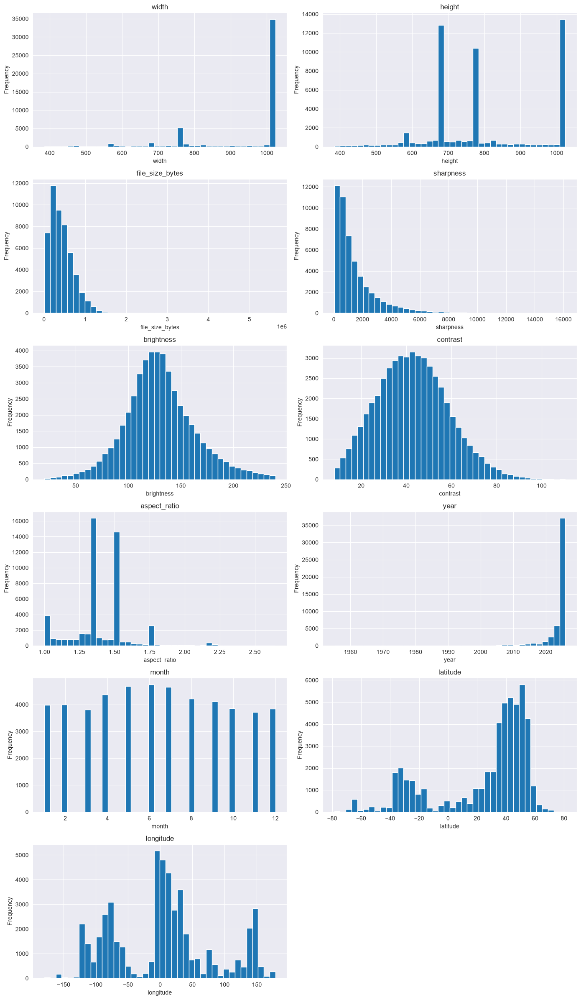

In [55]:
n = len(numeric_columns)
ncols = 2
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4 * nrows))
axes = axes.flatten()

for i, col in enumerate(numeric_columns):
    axes[i].hist(df[col].dropna(), bins=40)
    axes[i].set_title(col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

for i in range(n, len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

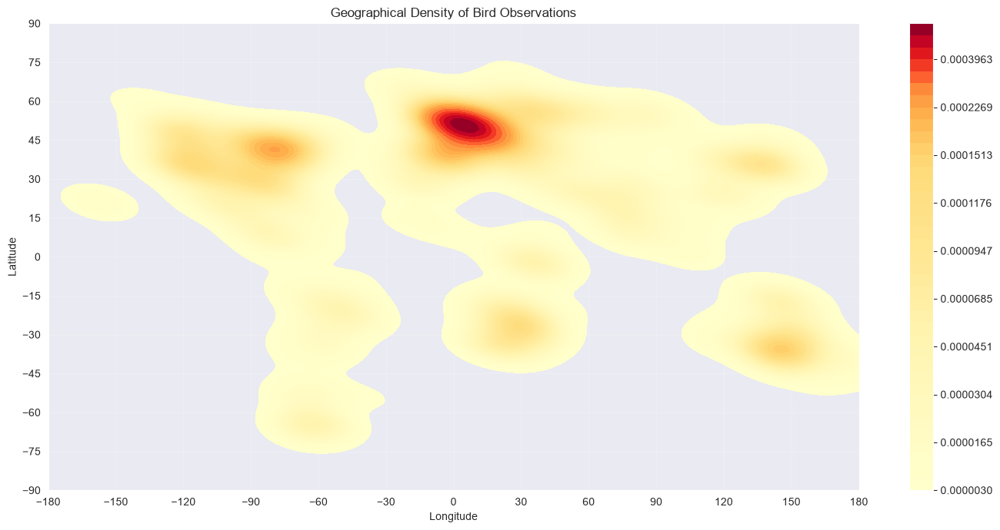

In [56]:
geo_df = df.dropna(subset=["longitude", "latitude"])

plt.figure(figsize=(14, 7))

sns.kdeplot(
    data=geo_df,
    x="longitude",
    y="latitude",
    fill=True,
    cmap="YlOrRd",
    levels=40,
    thresh=0.02,
    bw_adjust=0.8,
    cbar=True
)

plt.xlim(-180, 180)
plt.ylim(-90, 90)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographical Density of Bird Observations")

plt.xticks(np.arange(-180, 181, 30))
plt.yticks(np.arange(-90, 91, 15))

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

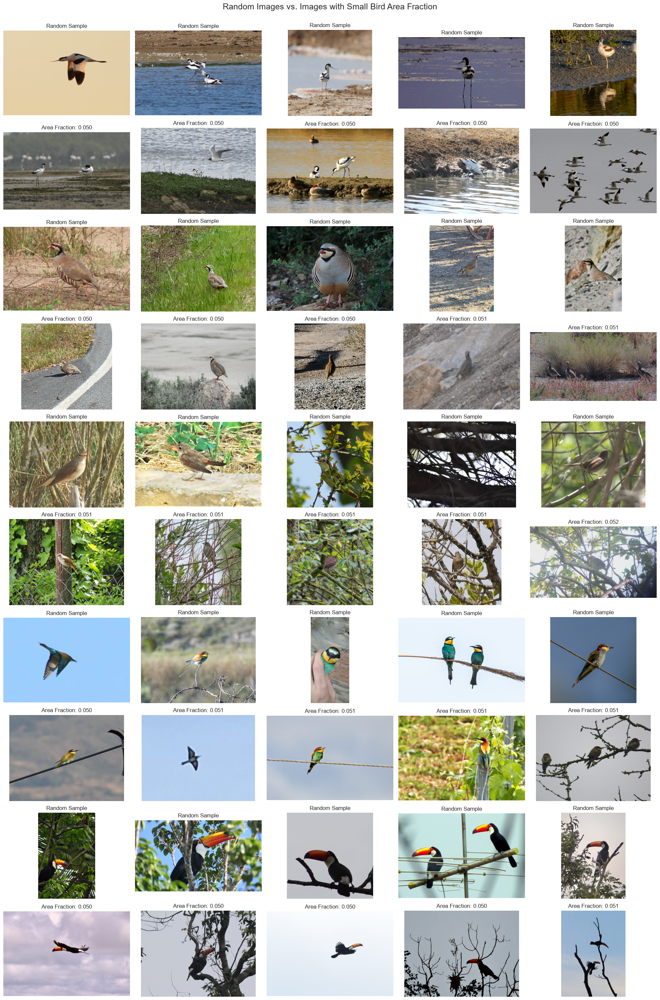

In [57]:
IMAGE_ROOT = Path("../inat_birds")

selected_species = (
    df["species_scientific"]
    .dropna()
    .drop_duplicates()
    .sample(n=5, random_state=42)
    .tolist()
)

fig, axes = plt.subplots(10, 5, figsize=(20, 30))

for i, species in enumerate(selected_species):

    species_df = df[
        df["species_scientific"] == species
    ].copy()

    species_df["bird_area_frac"] = pd.to_numeric(
        species_df["bird_area_frac"],
        errors="coerce"
    )

    species_df = species_df.dropna(
        subset=["bird_area_frac", "image_path"]
    )

    random_images = species_df.sample(
        n=5, random_state=42 + i
    )

    low_area_images = (
        species_df[
            ~species_df["image_path"].isin(random_images["image_path"])
        ]
        .nsmallest(5, "bird_area_frac")
    )

    if len(low_area_images) < 5:
        remaining = species_df[
            ~species_df["image_path"].isin(low_area_images["image_path"])
        ]
        low_area_images = pd.concat([
            low_area_images,
            remaining.nsmallest(5 - len(low_area_images), "bird_area_frac")
        ])


    for j, (_, row) in enumerate(random_images.iterrows()):

        image_path = IMAGE_ROOT / row["image_path"]

        ax = axes[2 * i, j]

        if image_path.exists():
            img = Image.open(image_path).convert("RGB")
            ax.imshow(img)
            ax.set_title("Random Sample")
        else:
            ax.set_title("Image Not Found")

        ax.axis("off")

    for j, (_, row) in enumerate(low_area_images.iterrows()):

        image_path = IMAGE_ROOT / row["image_path"]

        ax = axes[2 * i + 1, j]

        if image_path.exists():
            img = Image.open(image_path).convert("RGB")
            ax.imshow(img)
            ax.set_title(
                f"Area Fraction: {row['bird_area_frac']:.3f}"
            )
        else:
            ax.set_title("Image Not Found")

        ax.axis("off")

    axes[2 * i, 0].set_ylabel(
        f"{species}\nRandom",
        fontsize=11
    )

    axes[2 * i + 1, 0].set_ylabel(
        f"{species}\nSmall Bird Area",
        fontsize=11
    )

plt.suptitle(
    "Random Images vs. Images with Small Bird Area Fraction",
    fontsize=18,
    y=1.002
)

plt.tight_layout()
plt.show()

<div dir="rtl" align="right">

### تحلیل ماتریس همبستگی

برای بررسی روابط خطی میان ویژگی‌های تصویری، زمانی و جغرافیایی مجموعه‌داده، ماتریس همبستگی محاسبه و به‌صورت نمودار Heatmap نمایش داده شد.

نتایج نشان می‌دهد که بیشتر متغیرها همبستگی خطی ضعیفی با یکدیگر دارند. بااین‌حال، برخی روابط قابل‌توجه مشاهده می‌شود. از جمله، میان حجم فایل و وضوح تصویر همبستگی مثبت ۰.۴۰ و میان وضوح و کنتراست همبستگی مثبت ۰.۳۱ وجود دارد. این نتایج نشان می‌دهند که تصاویر با حجم فایل بیشتر و کنتراست بالاتر، به‌طور کلی تمایل به داشتن مقادیر وضوح بیشتری دارند.

همچنین میان عرض و ارتفاع تصویر و نیز میان ارتفاع و نسبت ابعاد، همبستگی منفی ۰.۴۱ مشاهده می‌شود. این روابط می‌توانند با نحوه تغییر اندازه و تنوع نسبت ابعاد تصاویر مرتبط باشند.

از سوی دیگر، همبستگی میان سال ثبت مشاهده و ویژگی‌های تصویری بسیار ضعیف است. همچنین متغیر ماه با سایر ویژگی‌ها رابطه خطی قابل‌توجهی نشان نمی‌دهد.

در مجموع، نتایج حاکی از آن است که به‌جز چند رابطه محدود، همبستگی خطی شدیدی میان ویژگی‌های بررسی‌شده وجود ندارد. این موضوع می‌تواند نشان‌دهنده وجود اطلاعات نسبتاً متفاوت در بسیاری از این ویژگی‌ها باشد. البته همبستگی پایین لزوماً به معنی استقلال متغیرها یا نبود روابط غیرخطی نیست.

</div>

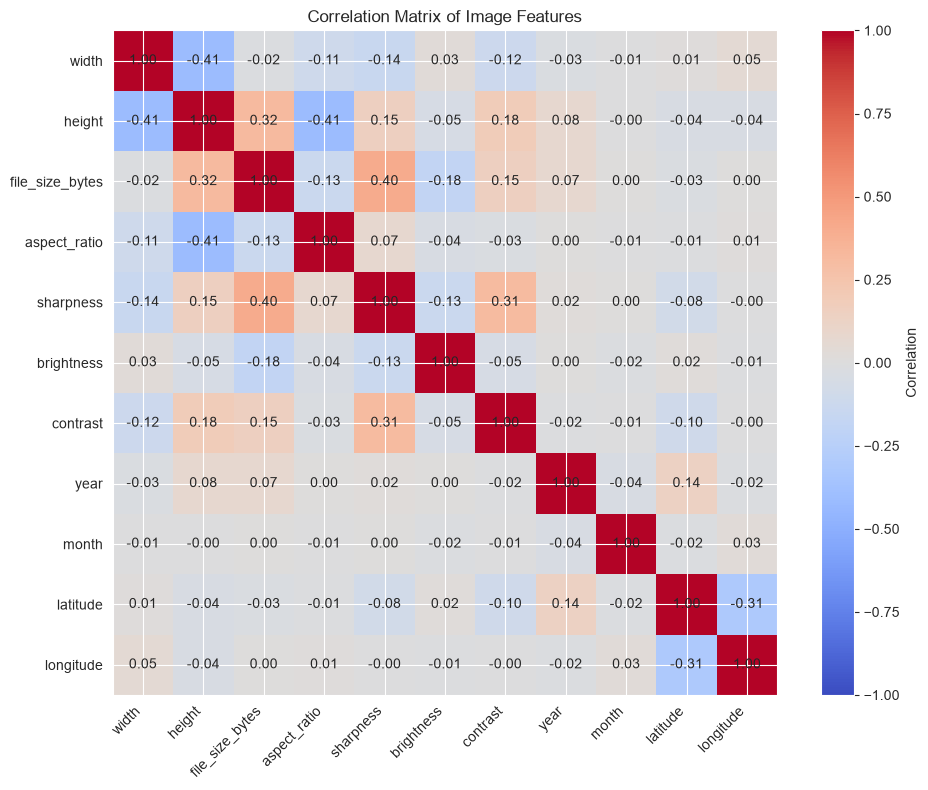

In [58]:
corr_columns = [
    "width",
    "height",
    "file_size_bytes",
    "aspect_ratio",
    "sharpness",
    "brightness",
    "contrast",
    "year",
    "month",
    "latitude",
    "longitude"
]

corr_matrix = df[corr_columns].corr()

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr_columns)))
ax.set_yticks(range(len(corr_columns)))

ax.set_xticklabels(corr_columns, rotation=45, ha="right")
ax.set_yticklabels(corr_columns)

for i in range(len(corr_columns)):
    for j in range(len(corr_columns)):
        ax.text(
            j, i,
            f"{corr_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.colorbar(im, ax=ax, label="Correlation")
plt.title("Correlation Matrix of Image Features")
plt.tight_layout()
plt.show()

<div dir="rtl" align="right">

### تحلیل روابط چندمتغیره

#### رابطه حجم فایل و وضوح تصویر

نمودار پراکندگی حجم فایل (`file_size_bytes`) و وضوح تصویر (`sharpness`) نشان‌دهنده یک رابطه مثبت بین این دو متغیر است. با افزایش حجم فایل، امکان مشاهده مقادیر بالاتر وضوح نیز بیشتر می‌شود. بااین‌حال، پراکندگی قابل‌توجه نقاط نشان می‌دهد که حجم فایل به‌تنهایی توضیح‌دهنده وضوح تصویر نیست.

#### رابطه کنتراست و وضوح تصویر

بررسی رابطه کنتراست (`contrast`) و وضوح تصویر (`sharpness`) نشان می‌دهد که با افزایش کنتراست، امکان مشاهده مقادیر بالاتر وضوح بیشتر می‌شود. بااین‌حال، این رابطه کاملاً خطی نیست و در مقادیر بالاتر کنتراست، پراکندگی وضوح تصاویر همچنان قابل‌توجه است.

#### رابطه سال ثبت مشاهده و وضوح تصویر

در بررسی رابطه سال ثبت مشاهده (`year`) و وضوح تصویر، تمرکز بیشتر مشاهدات در سال‌های اخیر، به‌ویژه بازه ۲۰۲۰ تا ۲۰۲۶، مشاهده می‌شود. همچنین در سال‌های مختلف پراکندگی قابل‌توجهی در مقادیر وضوح وجود دارد. با توجه به تعداد کمتر نمونه‌ها در سال‌های قدیمی‌تر، نمی‌توان از این نمودار به‌تنهایی روند مشخصی برای تغییر کیفیت تصاویر در طول زمان نتیجه گرفت.

#### پراکندگی جغرافیایی مشاهدات

نمودار پراکندگی مختصات جغرافیایی (`latitude` و `longitude`) نشان می‌دهد که تصاویر مجموعه‌داده توزیع یکنواختی در سطح جهان ندارند. تراکم تصاویر در مناطقی مانند آمریکای شمالی و اروپا بیشتر است، درحالی‌که برخی مناطق دیگر پوشش محدودتری دارند. این عدم توازن جغرافیایی می‌تواند در مراحل بعدی مدل‌سازی و ارزیابی تعمیم‌پذیری مدل اهمیت داشته باشد.

</div>

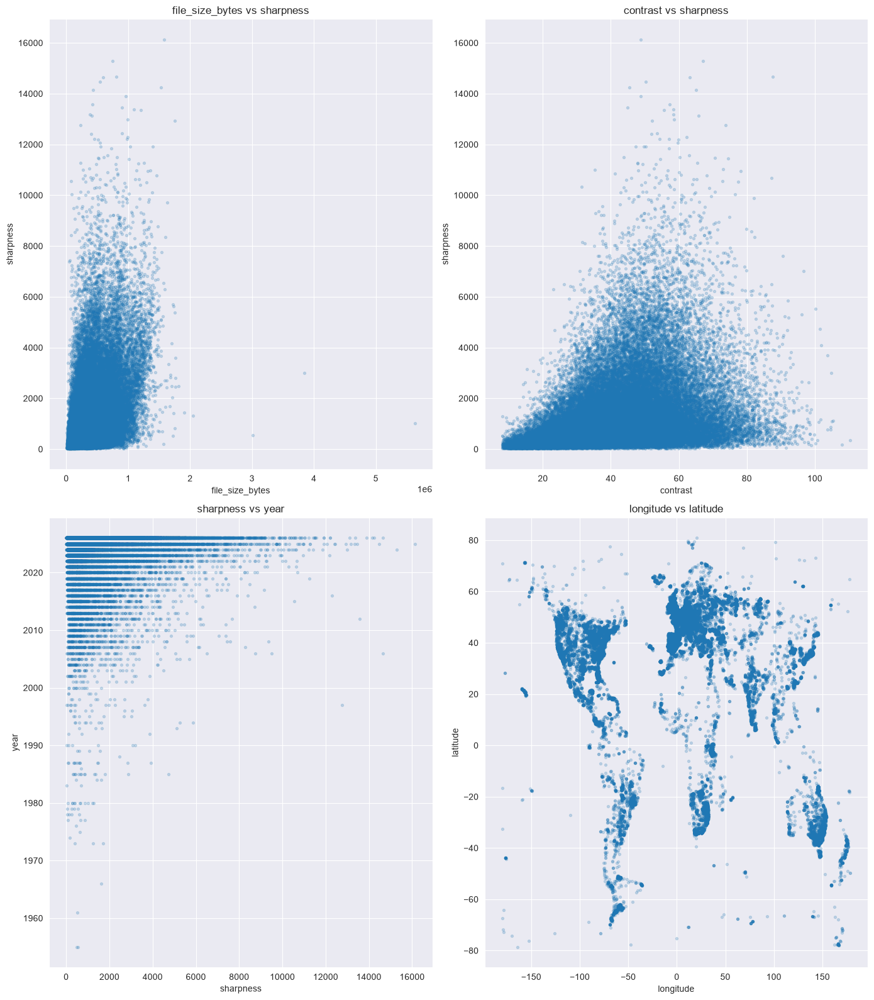

In [59]:
scatter_pairs = [
    ("file_size_bytes", "sharpness"),
    ("contrast", "sharpness"),
    ("sharpness", "year"),
    ("longitude", "latitude")
]

fig, axes = plt.subplots(2, 2, figsize=(14, 16))
axes = axes.flatten()

for i, (x, y) in enumerate(scatter_pairs):
    axes[i].scatter(df[x], df[y], alpha=0.2, s=8)
    axes[i].set_xlabel(x)
    axes[i].set_ylabel(y)
    axes[i].set_title(f"{x} vs {y}")


plt.tight_layout()
plt.show()

<div dir="rtl" align="right">

## تحلیل نمودارهای جعبه‌ای

### ۱. مقایسه وضوح تصاویر میان گونه‌های مختلف

نمودار جعبه‌ای وضوح تصویر (`sharpness`) در گونه‌های مختلف نشان می‌دهد که توزیع وضوح در میان گونه‌ها یکسان نیست. میانه و میزان پراکندگی وضوح برای برخی گونه‌ها تفاوت قابل‌توجهی دارد. همچنین در تعدادی از گونه‌ها دامنه تغییرات و پراکندگی مقادیر بیشتر است.

این تفاوت‌ها نشان می‌دهد که کیفیت تصاویر در کلاس‌های مختلف مجموعه‌داده یکنواخت نیست و ممکن است در مراحل بعدی بر عملکرد مدل طبقه‌بندی تأثیر بگذارد.

### ۲. بررسی پراکندگی طول جغرافیایی در گونه‌های مختلف

نمودار طول جغرافیایی (`longitude`) نشان می‌دهد که پراکندگی مختصات ثبت‌شده برای گونه‌های مختلف متفاوت است. در برخی گونه‌ها، جعبه‌ها کوتاه‌تر هستند که نشان‌دهنده تمرکز بیشتر ۵۰ درصد میانی مشاهدات در محدوده طول جغرافیایی محدودتری است. در مقابل، برخی گونه‌ها پراکندگی بیشتری در این متغیر دارند.

### ۳. بررسی پراکندگی عرض جغرافیایی در گونه‌های مختلف

در نمودار عرض جغرافیایی (`latitude`) نیز تفاوت قابل‌توجهی میان گونه‌ها مشاهده می‌شود. برخی گونه‌ها در بازه عرض جغرافیایی محدودتری ثبت شده‌اند، درحالی‌که برای برخی دیگر دامنه گسترده‌تری از مختصات وجود دارد.

نکته قابل‌توجه در بررسی هم‌زمان این دو نمودار، کوتاه بودن جعبه‌های برخی گونه‌ها در هر دو متغیر `longitude` و `latitude` است. این موضوع نشان می‌دهد که ۵۰ درصد میانی مختصات ثبت‌شده برای این گونه‌ها در بازه‌های جغرافیایی نسبتاً محدودی قرار دارند؛ به بیان دیگر، مشاهدات مربوط به برخی گونه‌ها ظاهراً در مناطق جغرافیایی مشخصی متمرکز شده‌اند.

این الگو می‌تواند ناشی از محدوده پراکنش طبیعی گونه‌ها یا سوگیری در مناطق ثبت مشاهدات در iNaturalist باشد. چنین تمرکزی از نظر پروژه اهمیت دارد؛ زیرا ممکن است مدل بتواند از اطلاعات جغرافیایی یا ویژگی‌های پس‌زمینه تصاویر برای تشخیص گونه‌ها استفاده کند، به‌جای آنکه صرفاً ویژگی‌های ظاهری پرنده را یاد بگیرد. البته این نمودارها به‌تنهایی اثبات‌کننده یادگیری میان‌بُر نیستند و برای بررسی دقیق‌تر آن به آزمایش‌های تکمیلی نیاز است.

### ۴. بررسی توزیع ماه ثبت تصاویر در گونه‌های مختلف

نمودار جعبه‌ای ماه ثبت تصاویر (`month`) برای گونه‌های مختلف نشان می‌دهد که در بیشتر گونه‌ها، تصاویر در ماه‌های مختلف سال پراکنده شده‌اند و تمرکز مشخصی روی یک ماه خاص مشاهده نمی‌شود. بااین‌حال، برای تعداد محدودی از گونه‌ها جعبه‌های کوچک‌تری دیده می‌شود که نشان‌دهنده تمرکز بیشتر ۵۰ درصد میانی مشاهدات در بازه ماهانه محدودتری است.

بنابراین، اگرچه برای بیشتر گونه‌ها الگوی زمانی مشخص و محدودی مشاهده نمی‌شود، توزیع ماهانه برخی گونه‌ها می‌تواند تا حدی متفاوت باشد. این موضوع از نظر احتمال استفاده ناخواسته مدل از فصل یا زمان ثبت تصویر اهمیت دارد؛ هرچند نمودار به‌تنهایی نشان نمی‌دهد که مدل الزاماً از این اطلاعات به‌عنوان میان‌بُر استفاده خواهد کرد.

### ۵. بررسی وضوح تصاویر در دهه‌های مختلف

نمودار وضوح تصویر (`sharpness`) در دهه‌های مختلف نشان می‌دهد که میانه و پراکندگی وضوح در بازه‌های زمانی متفاوت یکسان نیست. برای مثال، در دهه ۱۹۷۰ میانه وضوح پایین‌تری نسبت به برخی دهه‌های دیگر مشاهده می‌شود. همچنین در دهه‌های ۱۹۹۰ تا ۲۰۲۰ پراکندگی قابل‌توجهی در مقادیر وضوح وجود دارد.

این تفاوت‌ها می‌توانند ناشی از تغییر تجهیزات تصویربرداری، کیفیت تصاویر یا شرایط ثبت آن‌ها در دوره‌های مختلف باشند. بااین‌حال، برای تفسیر دقیق‌تر باید تعداد نمونه‌های هر دهه نیز در نظر گرفته شود؛ به‌ویژه در دهه‌های قدیمی‌تر که تعداد مشاهدات احتمالاً محدودتر است.

### ۶. بررسی روشنایی تصاویر در ماه‌های مختلف

نمودار روشنایی (`brightness`) در ماه‌های مختلف نشان می‌دهد که میانه روشنایی تصاویر در طول سال نسبتاً ثابت است. همچنین محدوده بین چارک اول و سوم در بیشتر ماه‌ها شباهت زیادی دارد.

بنابراین، در نمونه‌های بررسی‌شده تفاوت چشمگیری در توزیع روشنایی تصاویر میان ماه‌های مختلف مشاهده نمی‌شود. البته این نتیجه به معنی یکسان بودن شرایط نوری تمام تصاویر نیست؛ زیرا در هر ماه همچنان پراکندگی قابل‌توجهی از مقادیر روشنایی وجود دارد.

</div>

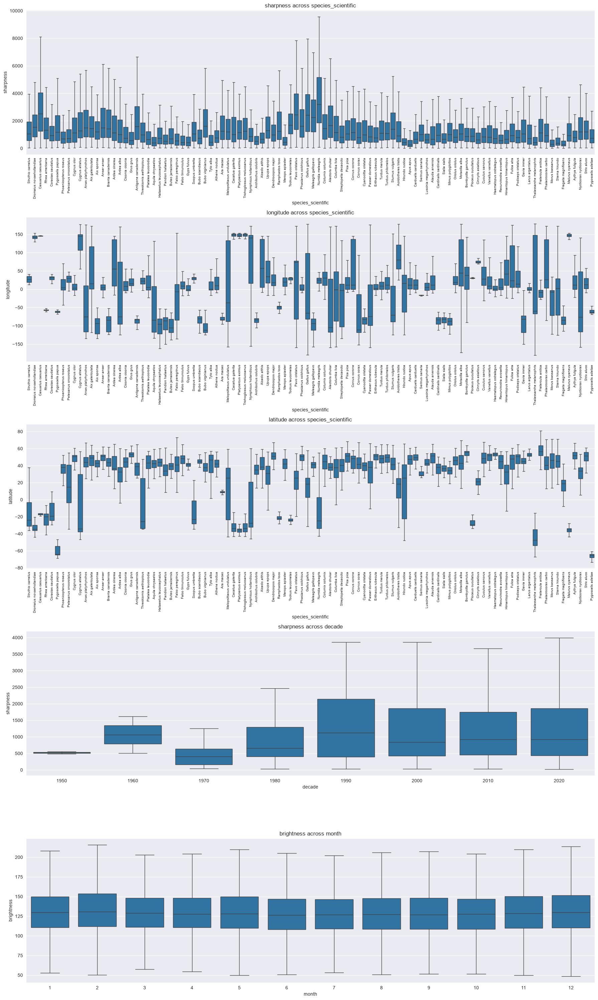

In [60]:
import math

boxplot_pairs = [
    ("species_scientific", "sharpness"),
    ("species_scientific", "longitude"),
    ("species_scientific", "latitude"),
    ("decade", "sharpness"),
    ("month", "brightness"),
]

time_df = df.copy()
time_df["decade"] = (time_df["year"] // 10) * 10

n = len(boxplot_pairs)
ncols = 1
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(18, 6 * nrows))
axes = axes.flatten()

for ax, (x, y) in zip(axes, boxplot_pairs):
    data = time_df if x == "decade" else df

    sns.boxplot(
        data=data,
        x=x,
        y=y,
        showfliers=False,
        ax=ax
    )

    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(f"{y} across {x}")

    if x == "species_scientific":
        ax.tick_params(axis="x", rotation=90, labelsize=7)

for i in range(n, len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

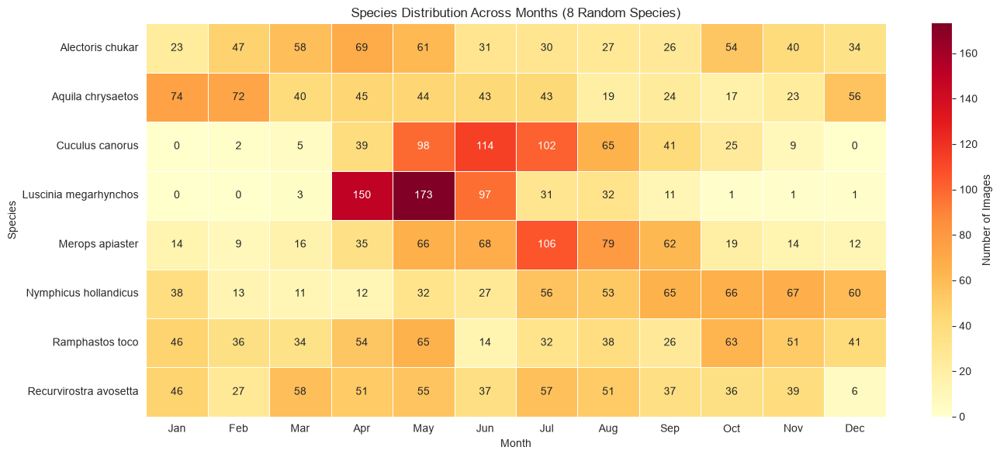

In [61]:
selected_species = (
    df["species_scientific"]
    .dropna()
    .drop_duplicates()
    .sample(n=8, random_state=42)
)

subset = df[df["species_scientific"].isin(selected_species)]

heatmap_data = pd.crosstab(
    subset["species_scientific"],
    subset["month"]
)

heatmap_data = heatmap_data.reindex(columns=range(1, 13), fill_value=0)

plt.figure(figsize=(14, 6))

sns.heatmap(
    heatmap_data,
    cmap="YlOrRd",
    annot=True,
    fmt="d",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Number of Images"}
)

plt.xlabel("Month")
plt.ylabel("Species")
plt.title("Species Distribution Across Months (8 Random Species)")

plt.xticks(
    ticks=[i + 0.5 for i in range(12)],
    labels=["Jan", "Feb", "Mar", "Apr", "May", "Jun",
            "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    rotation=0
)

plt.tight_layout()
plt.show()

<div dir="rtl" align="right">

### تحلیل توزیع تعداد تصاویر در سال‌های مختلف

بررسی تعداد تصاویر ثبت‌شده در سال‌های مختلف نشان می‌دهد که توزیع زمانی نمونه‌ها یکنواخت نیست. بیشترین تعداد تصاویر مربوط به سال ۲۰۲۶ است و پس از آن سال ۲۰۲۵ قرار دارد؛ به‌طوری‌که تعداد تصاویر این دو سال با اختلاف قابل‌توجهی بیشتر از سال‌های دیگر است.

این الگو نشان‌دهنده تمرکز بخش عمده‌ای از داده‌ها در سال‌های اخیر است. این موضوع می‌تواند تحت تأثیر افزایش فعالیت کاربران در پلتفرم iNaturalist، رشد تعداد مشاهدات ثبت‌شده و دسترسی بیشتر به تصاویر جدید باشد.

در مقابل، تعداد کمتر تصاویر در سال‌های قدیمی‌تر می‌تواند نشان‌دهنده پوشش زمانی محدودتر مجموعه‌داده در این دوره‌ها باشد. بنابراین، مجموعه‌داده از نظر زمانی دارای عدم توازن است و این مسئله باید در طراحی آزمایش‌ها و ارزیابی تعمیم‌پذیری مدل مورد توجه قرار گیرد.

</div>

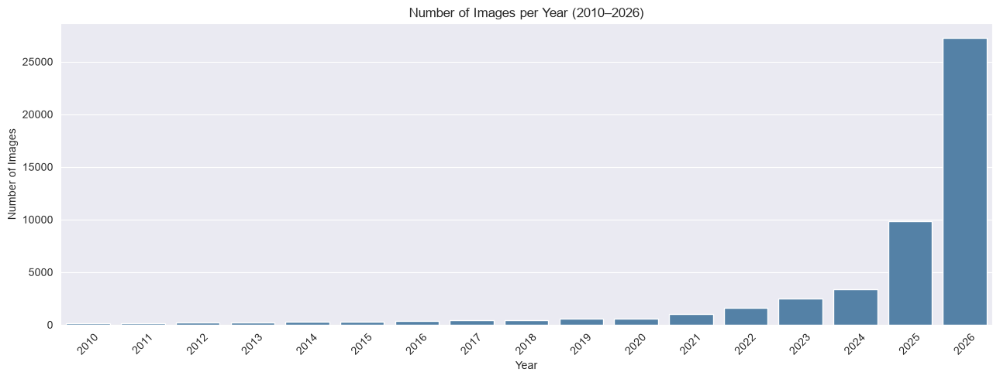

In [62]:
year_counts = df["year"].value_counts().sort_index()
year_counts = year_counts[year_counts.index >= 2010]

plt.figure(figsize=(13, 5))

sns.barplot(
    x=year_counts.index,
    y=year_counts.values,
    color="steelblue"
)

plt.xlabel("Year")
plt.ylabel("Number of Images")
plt.title("Number of Images per Year (2010–2026)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()